In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/archive (4).zip")

In [3]:
print("Columns in dataset:", df.columns.tolist())
target_features = ['bedrooms', 'sqft_living', 'grade', 'yr_built']
display(df[target_features].describe())


Columns in dataset: ['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


,bedrooms,sqft_living,grade,yr_built
count,21613.000000,21613.000000,21613.000000,21613.000000
mean,3.370842,2079.899736,7.656873,1971.005136
std,0.930062,918.440897,1.175459,29.373411
min,0.000000,290.000000,1.000000,1900.000000
25%,3.000000,1427.000000,7.000000,1951.000000
50%,3.000000,1910.000000,7.000000,1975.000000
75%,4.000000,2550.000000,8.000000,1997.000000
max,33.000000,13540.000000,13.000000,2015.000000


/tmp/ipykernel_628/1132033899.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='grade', data=df, ax=axes[1, 0], palette='viridis')


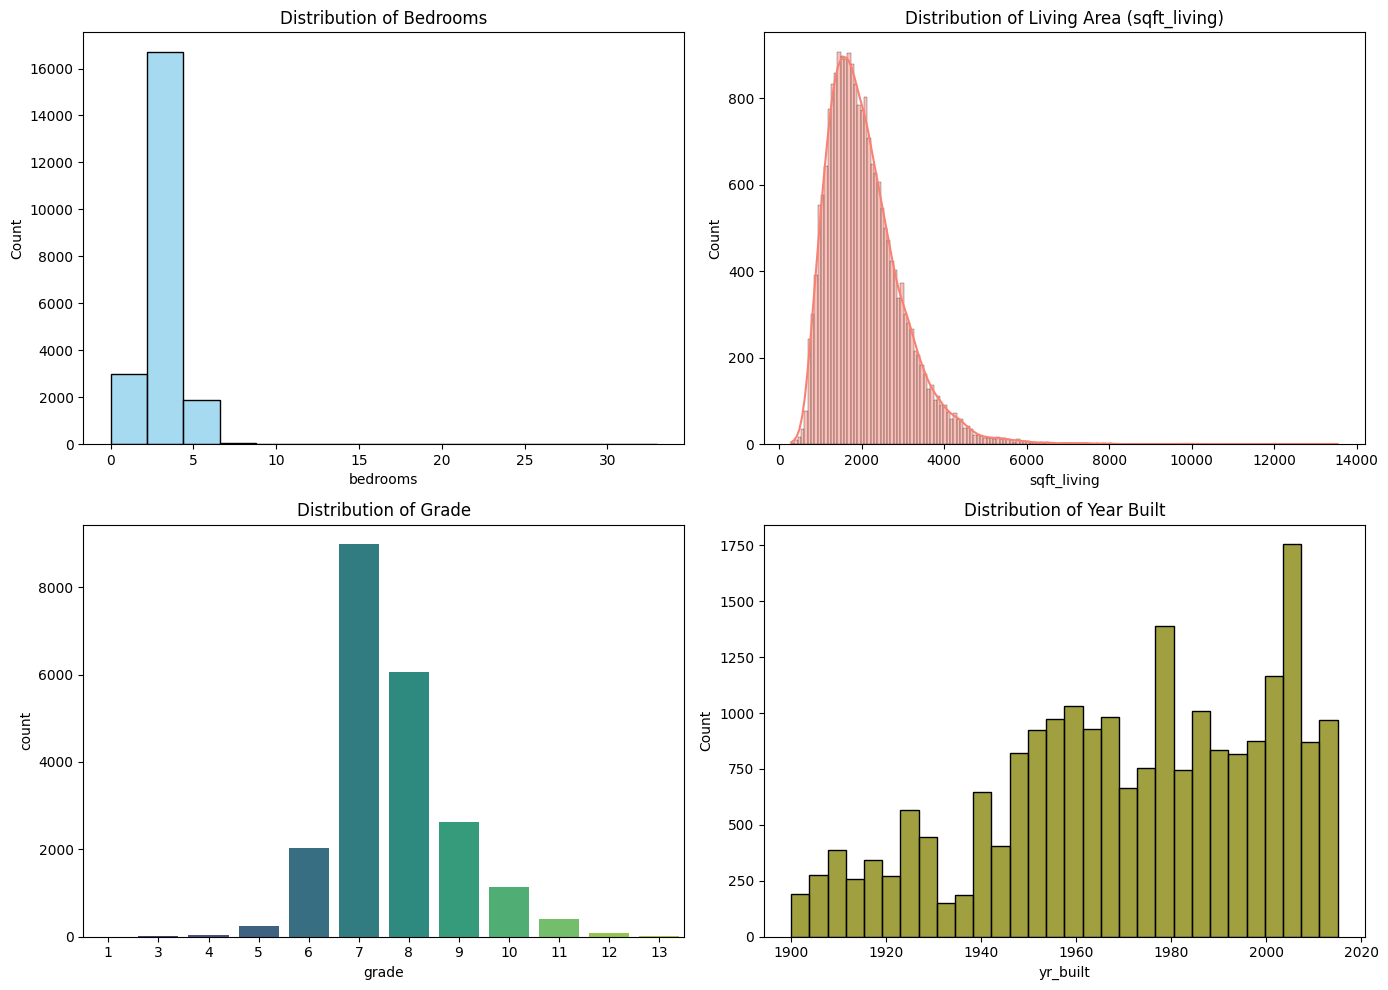

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['bedrooms'], kde=False, ax=axes[0, 0], bins=15, color='skyblue')
axes[0, 0].set_title('Distribution of Bedrooms')

sns.histplot(df['sqft_living'], kde=True, ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Distribution of Living Area (sqft_living)')

sns.countplot(x='grade', data=df, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Distribution of Grade')

sns.histplot(df['yr_built'], kde=False, ax=axes[1, 1], bins=30, color='olive')
axes[1, 1].set_title('Distribution of Year Built')

plt.tight_layout()
plt.show()

In [5]:
df['date'] = pd.to_datetime(df['date'].str.slice(0, 8), format='%Y%m%d')

df['sale_year'] = df['date'].dt.year

df['property_age'] = df['sale_year'] - df['yr_built']

df['is_renovated'] = df['yr_renovated'].apply(lambda x: 1 if x > 0 else 0)
display(df[['date', 'sale_year', 'yr_built', 'property_age', 'yr_renovated', 'is_renovated']].head())

,date,sale_year,yr_built,property_age,yr_renovated,is_renovated
0,2014-10-13,2014,1955,59,0,0
1,2014-12-09,2014,1951,63,1991,1
2,2015-02-25,2015,1933,82,0,0
3,2014-12-09,2014,1965,49,0,0
4,2015-02-18,2015,1987,28,0,0


In [6]:
df['price_per_sqft'] = df['price'] / df['sqft_living']
display(df[['price', 'sqft_living', 'price_per_sqft']].describe())
display(df[['price', 'sqft_living', 'price_per_sqft']].head())

,price,sqft_living,price_per_sqft
count,2.161300e+04,21613.000000,21613.000000
mean,5.400881e+05,2079.899736,264.156594
std,3.671272e+05,918.440897,110.060793
min,7.500000e+04,290.000000,87.588235
25%,3.219500e+05,1427.000000,182.291667
50%,4.500000e+05,1910.000000,244.644550
75%,6.450000e+05,2550.000000,318.322981
max,7.700000e+06,13540.000000,810.138889


,price,sqft_living,price_per_sqft
0,221900.0,1180,188.050847
1,538000.0,2570,209.338521
2,180000.0,770,233.766234
3,604000.0,1960,308.163265
4,510000.0,1680,303.571429


In [7]:
missing_counts = df.isnull().sum()
print("Missing values per column:")
print(missing_counts[missing_counts > 0])

zero_bedrooms = (df['bedrooms'] == 0).sum()
zero_bathrooms = (df['bathrooms'] == 0).sum()
print(f"\nProperties with 0 bedrooms: {zero_bedrooms}")
print(f"Properties with 0 bathrooms: {zero_bathrooms}")

display(df[df['bedrooms'] == 0][['price', 'bedrooms', 'bathrooms', 'sqft_living']].head())

bedroom_median = df[df['bedrooms'] > 0]['bedrooms'].median()
bathroom_median = df[df['bathrooms'] > 0]['bathrooms'].median()

df['bedrooms'] = df['bedrooms'].replace(0, bedroom_median)
df['bathrooms'] = df['bathrooms'].replace(0, bathroom_median)

print(f"\nAfter cleaning:")
print(f"Properties with 0 bedrooms: {(df['bedrooms'] == 0).sum()}")
print(f"Properties with 0 bathrooms: {(df['bathrooms'] == 0).sum()}")

Missing values per column:
Series([], dtype: int64)

Properties with 0 bedrooms: 13
Properties with 0 bathrooms: 10


,price,bedrooms,bathrooms,sqft_living
875,1095000.0,0,0.0,3064
3119,380000.0,0,0.0,1470
3467,288000.0,0,1.5,1430
4868,228000.0,0,1.0,390
6994,1295650.0,0,0.0,4810



After cleaning:
Properties with 0 bedrooms: 0
Properties with 0 bathrooms: 0


In [8]:
df['age_at_renovation'] = df.apply(
    lambda row: row['yr_renovated'] - row['yr_built'] if row['is_renovated'] == 1 else 0,
    axis=1
)

df['years_since_renovation'] = df.apply(
    lambda row: row['sale_year'] - row['yr_renovated'] if row['is_renovated'] == 1 else row['property_age'],
    axis=1
)

display(df[['property_age', 'age_at_renovation', 'years_since_renovation']].describe())

display(df[df['is_renovated'] == 1][['yr_built', 'yr_renovated', 'sale_year', 'property_age', 'age_at_renovation', 'years_since_renovation']].head())

,property_age,age_at_renovation,years_since_renovation
count,21613.000000,21613.000000,21613.000000
mean,43.317818,2.380882,40.936936
std,29.375493,12.359528,28.813643
min,-1.000000,0.000000,-1.000000
25%,18.000000,0.000000,15.000000
50%,40.000000,0.000000,37.000000
75%,63.000000,0.000000,60.000000
max,115.000000,114.000000,115.000000


,yr_built,yr_renovated,sale_year,property_age,age_at_renovation,years_since_renovation
1,1951,1991,2014,63,40,23
35,1930,2002,2014,84,72,12
95,1946,1991,2014,68,45,23
103,1950,2010,2014,64,60,4
115,1900,1999,2014,114,99,15


In [ ]:
df['price_per_sqft_living'] = df['price'] / df['sqft_living']
df['price_per_sqft_lot'] = df['price'] / df['sqft_lot']
display(df[['price', 'sqft_living', 'price_per_sqft_living', 'sqft_lot', 'price_per_sqft_lot']].describe())

display(df[['price', 'price_per_sqft_living', 'price_per_sqft_lot']].head())

Q1 (25th percentile): $321,950.00
Q3 (75th percentile): $645,000.00
IQR: $323,050.00
Lower Bound for outliers: $-162,625.00
Upper Bound for outliers: $1,129,575.00
Total properties: 21613
Number of price outliers: 1146 (5.30% of data)


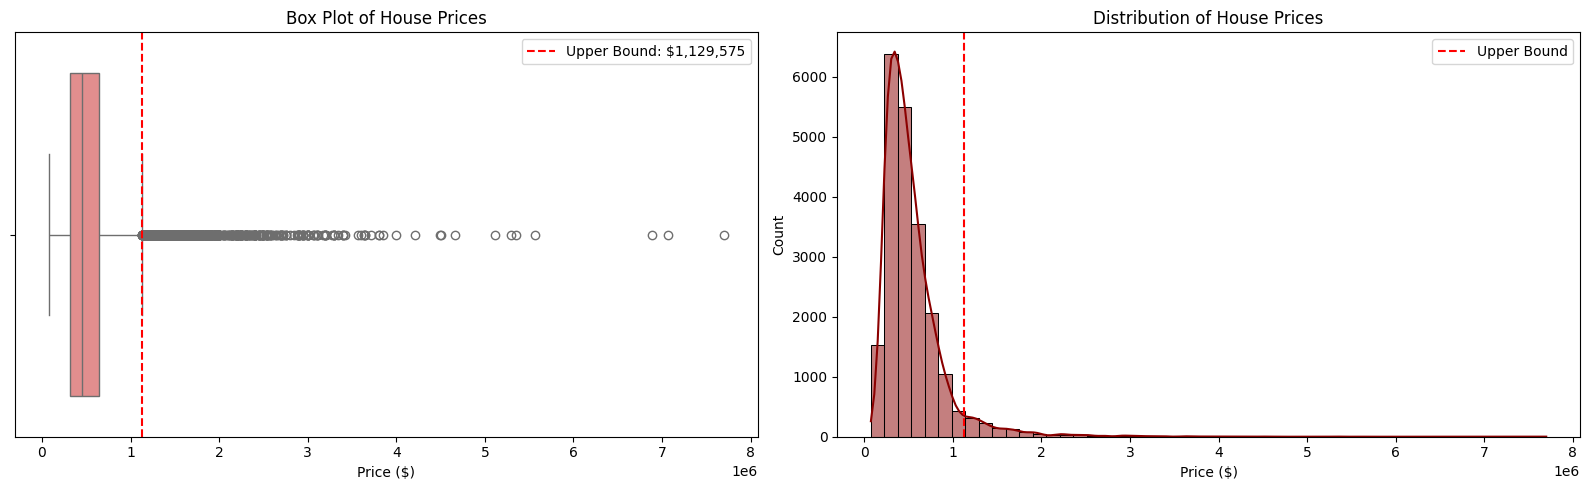


Top 5 extreme valuation outliers:


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,lat,long,sqft_living15,sqft_lot15,sale_year,property_age,is_renovated,price_per_sqft,age_at_renovation,years_since_renovation
7252,6762700020,2014-10-13,7700000.0,6,8.00,12050,27600,2.5,0,3,...,47.6298,-122.323,3940,8800,2014,104,1,639.004149,77,27
3914,9808700762,2014-06-11,7062500.0,5,4.50,10040,37325,2.0,1,2,...,47.6500,-122.214,3930,25449,2014,74,1,703.436255,61,13
9254,9208900037,2014-09-19,6885000.0,6,7.75,9890,31374,2.0,0,4,...,47.6305,-122.240,4540,42730,2014,13,0,696.157735,0,13
4411,2470100110,2014-08-04,5570000.0,5,5.75,9200,35069,2.0,0,0,...,47.6289,-122.233,3560,24345,2014,13,0,605.434783,0,13
1448,8907500070,2015-04-13,5350000.0,5,5.00,8000,23985,2.0,0,4,...,47.6232,-122.220,4600,21750,2015,6,0,668.750000,0,6


In [9]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]

print(f"Q1 (25th percentile): ${Q1:,.2f}")
print(f"Q3 (75th percentile): ${Q3:,.2f}")
print(f"IQR: ${IQR:,.2f}")
print(f"Lower Bound for outliers: ${lower_bound:,.2f}")
print(f"Upper Bound for outliers: ${upper_bound:,.2f}")
print(f"Total properties: {len(df)}")
print(f"Number of price outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}% of data)")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(x=df['price'], ax=axes[0], color='lightcoral')
axes[0].axvline(upper_bound, color='red', linestyle='--', label=f'Upper Bound: ${upper_bound:,.0f}')
axes[0].set_title('Box Plot of House Prices')
axes[0].set_xlabel('Price ($)')
axes[0].legend()

sns.histplot(df['price'], kde=True, ax=axes[1], color='darkred', bins=50)
axes[1].axvline(upper_bound, color='red', linestyle='--', label=f'Upper Bound')
axes[1].set_title('Distribution of House Prices')
axes[1].set_xlabel('Price ($)')
axes[1].legend()

plt.tight_layout()
plt.show()

print("\nTop 5 extreme valuation outliers:")
display(df.sort_values(by='price', ascending=False).head(5))